## DM optimization for the brightest Pband burst

In [1]:
import numpy as np
import pandas as pd
import your
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import sys
#sys.path.append('/Users/dante/Documents/eclat/scripts')
#import basic_funcs
from matplotlib import colors
from scipy.optimize import curve_fit, leastsq
import numpy.ma as ma
import matplotlib.ticker as ticker

In [2]:
def gaus(x,a,x0,sigma,d):
    return a*np.exp(-(x-x0)**2/(2*sigma**2))+d

In [3]:
def downsample(data, freqf, timef):
    """ Downsamples a 2D array in time and or frequency"""
    
    nchan = data.shape[0]
    nsamps = data.shape[1]
    
    assert nchan % freqf == 0
    
    remainder = nsamps % timef
    if remainder > 0:
        print(f"Warning: removing the last {remainder} samples of the time-axis")
        print(f'Old shape (before downsampling): {data.shape}')
        data = data[:, :-remainder]
        print(f'Old shape (before downsampling): {data.shape}')
           
    data_down = data.reshape(-1, data.shape[-1]//timef, timef).mean(axis=2)
    data_down = data_down.reshape(-1, freqf, data_down.shape[-1]).mean(axis=1)
    return data_down

def dedisperse(data, dm, freqs, tsamp, dmconst=1.0 / (2.41 * 10.0**-4.0)):
    """
    Parameters
    ----------
    data : 2d numpy array
        data containing freq on the y-axis and time on the x-axis
    dm : float
        Dispersion measure in units of pc / cc.
    freqs : 1d numpy array
        Array containing the channel frequencies in units of MHz
    tsamp : float
        sampling time in units of seconds.
    dmconst: float
        dispersion constant in units of MHz^2 pc^-1 cm^3 s
        according to K Nimmo (https://ui.adsabs.harvard.edu/abs/2022NatAs...6..393N/abstract)
        this is also the value that is used in dspsr (digifil) and SFXC

    Returns
    -------
    ndata : 2d numpy
        dedispersed data

    """
    # set up freq info
    freqs = freqs.astype(np.float64)
    reffreq = np.max(freqs)
    
    # init empty array to store dedisp data in
    ndata = np.zeros(data.shape)
    
    # calculate time shifts and convert to bin shifts
    time_shift = dmconst * dm * (reffreq**-2.0 - freqs**-2.0)
    
    # round to nearest integer
    bin_shift = np.rint((time_shift / tsamp)).astype(np.int64)
    
    # checks
    assert len(bin_shift) == data.shape[0]
    assert ndata.shape == data.shape
    
    # dedisperse by rolling back the channels
    for i, bs in enumerate(bin_shift):
        ndata[i, :] = np.roll(data[i, :], bs)
        
    return ndata
    

def clone_cols(arr, n):
    """
    Parameters
    ----------
    arr : 2d-numpy array with shape k x m (rows x colums)
        input array that needs to be super-sampled.
    n : int
        supersampling factor.

    Returns
    -------
    narr : super-sampled 2d-numpy array with shape k x (m * n).
    
    Example
    -------
    arr = array([[0, 1, 2],
                 [3, 4, 5]])
    arr2 = clone_cols(arr, 3)
    >>> array([[0, 0, 0, 1, 1, 1, 2, 2, 2],
               [3, 3, 3, 4, 4, 4, 5, 5, 5]])
    
    """

    narr = np.zeros(shape=(arr.shape[0], arr.shape[1] * n), dtype=arr.dtype)
    
    for i in range(arr.shape[1]):
        narr[:, (i*n):((i+1)*n)] = arr[:, i][:, None]
    
    return narr


def super_dedisperse(data, dm, freqs, tsamp, nfac, dmconst=1.0 / (2.41 * 10.0**-4.0)):
    """
    Parameters
    ----------
    data : 2d numpy array
        data containing freq on the y-axis and time on the x-axis
    dm : float
        Dispersion measure in units of pc / cc.
    freqs : 1d numpy array
        Array containing the channel frequencies in units of MHz
    tsamp : float
        sampling time in units of seconds.
    nfac : int
        Integer to speficy by how much to 'increase' the sampling time by
    dmconst: float
        dispersion constant in units of MHz^2 pc^-1 cm^3 s
        according to K Nimmo (https://ui.adsabs.harvard.edu/abs/2022NatAs...6..393N/abstract)
        this is also the value that is used in dspsr (digifil) and SFXC

    Returns
    -------
    ndata : 2d numpy
        dedispersed data

    """
    # set up freq info
    freqs = freqs.astype(np.float64)
    reffreq = np.max(freqs)
    
    # duplicate columns of our data
    data_sup = clone_cols(data, nfac)
    
    # init empty array to store dedisp data in
    ndata = np.zeros(data_sup.shape)
    
    # calculate time shifts and convert to bin shifts
    time_shift = dmconst * dm * (reffreq**-2.0 - freqs**-2.0)
    # round to nearest integer
    sup_bin_shift = np.rint((nfac * time_shift / tsamp)).astype(np.int64)
        
    # checks
    assert len(sup_bin_shift) == data_sup.shape[0]
    
    assert ndata.shape == data_sup.shape
    
    # dedisperse by rolling back the channels
    for i, bs in enumerate(sup_bin_shift):
        ndata[i, :] = np.roll(data_sup[i, :], bs)
        
    # downsample the data back in time
    ndata = downsample(data=ndata, freqf=1, timef=nfac)
        
    return ndata


def super_dedisperse2(data_sup, dm, freqs, tsamp, nfac, dmconst=1.0 / (2.41 * 10.0**-4.0)):
    """
    Parameters
    ----------
    data_sup : 2d numpy array
        super-sampled data containing freq on the y-axis and time on the x-axis
    dm : float
        Dispersion measure in units of pc / cc.
    freqs : 1d numpy array
        Array containing the channel frequencies in units of MHz
    tsamp : float
        sampling time in units of seconds.
    nfac : int
        Integer to speficy by how much to 'increase' the sampling time by
    dmconst: float
        dispersion constant in units of MHz^2 pc^-1 cm^3 s
        according to K Nimmo (https://ui.adsabs.harvard.edu/abs/2022NatAs...6..393N/abstract)
        this is also the value that is used in dspsr (digifil) and SFXC

    Returns
    -------
    ndata : 2d numpy
        dedispersed data
        
    Extra
    -----
    Should be used if the same dynamic spectrum is going to be dedispersed over a range
    of trial DMs. If only one DM is going to be used see the function super_dedisperse()

    """
    # set up freq info
    freqs = freqs.astype(np.float64)
    reffreq = np.max(freqs)
    
    # init empty array to store dedisp data in
    ndata = np.zeros(data_sup.shape)
    
    # calculate time shifts and convert to bin shifts
    time_shift = dmconst * dm * (reffreq**-2.0 - freqs**-2.0)
    # round to nearest integer
    sup_bin_shift = np.rint((nfac * time_shift / tsamp)).astype(np.int64)
        
    # checks
    assert len(sup_bin_shift) == data_sup.shape[0]
    
    assert ndata.shape == data_sup.shape
    
    # dedisperse by rolling back the channels
    for i, bs in enumerate(sup_bin_shift):
        ndata[i, :] = np.roll(data_sup[i, :], bs)
        
    # downsample the data back in time
    ndata = downsample(data=ndata, freqf=1, timef=nfac)
        
    return ndata

In [4]:
def normalize(ds,op):
    ds=ds.copy().astype(float)
    op=op.copy().astype(float)
    nds=np.zeros_like(ds)

    for chan in range(ds.shape[0]):
        channel=ds[chan,:]
        offburstchannel=op[chan,:]

        chan_mean=np.median(offburstchannel)
        chan_std=np.std(offburstchannel)
        if chan_std != 0:
            newchannel=(channel-chan_mean)/chan_std

        nds[chan,:]=newchannel

    return nds

In [5]:
def de_dedisp(y):
    """
    The burst is already dedisped by SFXC
    Will de-disperse the burst by giving a negative DM
    """
    
    tsamp = y.your_header.tsamp #in seconds
    nbins = y.your_header.nspectra 
    
    #time increasing, freq decreasing
    print("loading in the data")
    d = y.get_data(0,nbins,npoln=1)
    
    freqs = y.chan_freqs # in Mhz
    
    print("de-de-dispersing")
    stokes_i_dd = dedisperse(d.T,-219.7,freqs,tsamp) 
    
    print("dedispersing")
    max_sn = []
    
    dm_list = np.arange(219,222,.001)
    #dm_list = np.arange(218,221,.0001)
    for dm_dedisp in tqdm(dm_list):
        
        stokes_i = dedisperse(stokes_i_dd,dm_dedisp,freqs,tsamp)

        norm_v1=10 
        norm_v2=8000 
        stokes_i = normalize(stokes_i,stokes_i[:,norm_v1:norm_v2])

        #make profile
        prof = np.mean(stokes_i,axis=0)
        offprof = prof[norm_v1:norm_v2]
        offprof_std = np.std(offprof)
        offprof_mean = np.mean(offprof)   
        stokes_i_normprof = (prof - offprof_mean) / offprof_std
        stokes_i_normprof = stokes_i_normprof[10000:10500] #hardcoded 60ms

        sn_peak = np.max(stokes_i_normprof)
        max_sn.append(sn_peak)

    df = pd.DataFrame(data = {"DM":dm_list,\
                              "SN":max_sn})
    
    df.to_csv("dm-trials-2197.csv",header=True, index=True)

    return df

In [6]:
burst1 = your.Your('/data1/omar/sfxc/r117/p11749_30_p/p11749_30_256us_32KHz_StokesI_DM2197_cor_Wb.fil')
#This was already run a while ago :) 
#df_dm_trials = de_dedisp(y=burst1)

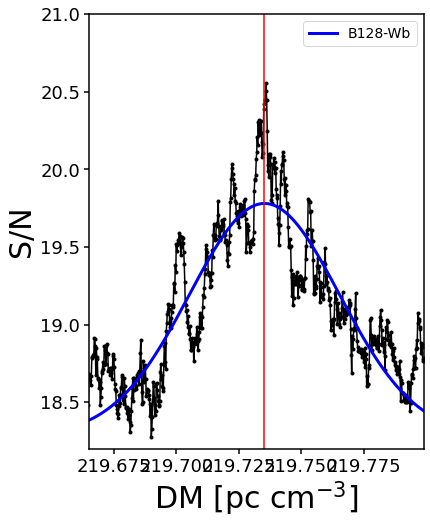

max 219.7358000000576
[1.49342524e+00 2.19735294e+02 3.00754034e-02 1.82862796e+01]
gerr [0.03382973 0.00046346 0.00094109 0.03401699]
219.735 0.001


In [7]:
def sn_vs_dm_1peak(csv):

    df = pd.read_csv(csv, sep=",", header=0, index_col=0)

    #Filter on the DM grid that has to be fitted, we don't want to take into account a wider dm-range 
    df_filter = df[(df['DM'] > 219.65) & (df['DM'] < 219.8)] 
    sn_filter = df_filter["SN"].values
    dm_filter = df_filter["DM"].values

    poptc,pcovc=curve_fit(gaus, dm_filter, sn_filter, p0=[20,219.7,0.1,200], maxfev=10000)
    
    #Retrieving the entire grid space from the df
    sn_range = df["SN"].values 
    dm_range = df["DM"].values 
    
    ##Figure
    fig,ax=plt.subplots(figsize=(6,8))
    
    #Plotting the whole range
    plt.plot(dm_range, sn_range,'.',color='k',ls='-')
    
    #Plotting only the gaussian
    dm_space = np.linspace(dm_filter[0], dm_filter[-1], 10000)
    plt.plot(dm_space,gaus(dm_space,*poptc),color='b',lw=3,label='B128-Wb')
    
    plt.axvline(poptc[1],color='red')
    #plt.axvline(poptc[1]+poptc[2]/np.sqrt(len(dm_range)),color='red',ls='--',alpha=0.45)
    #plt.axvline(poptc[1]-poptc[2]/np.sqrt(len(dm_range)),color='red',ls='--',alpha=0.45)
    
    for axis in ['top', 'bottom', 'left', 'right']:
        ax.spines[axis].set_linewidth(1.5)
        ax.tick_params(axis='both', which='major', labelsize=18, width=1.5, length=5)
        
    plt.xlabel(r'DM [pc cm$^{-3}]$',size=30)
    plt.ylabel('S/N',size=30)
    plt.ylim(18.2,21)
    plt.xlim(219.665,219.799)
    
    plt.legend(fontsize=14)
    plt.savefig('snvdm_wb_p.pdf',dpi=300)
    plt.show()
    
    print(f'max {dm_range[np.argmax(sn_range)]}')
    print(f"{poptc}")
    print(f'gerr {np.sqrt(np.diag(pcovc))}')
    print(f'{np.round(poptc[1],3)} {np.round(3*poptc[2]/np.sqrt(len(dm_range)),3)}')
    
    return

sn_vs_dm_1peak(csv="dm-trials-21937.csv")

[-2629.0, 5563.000000000001, 300.0, 356.0]
loading in the data
de-de-dispersing


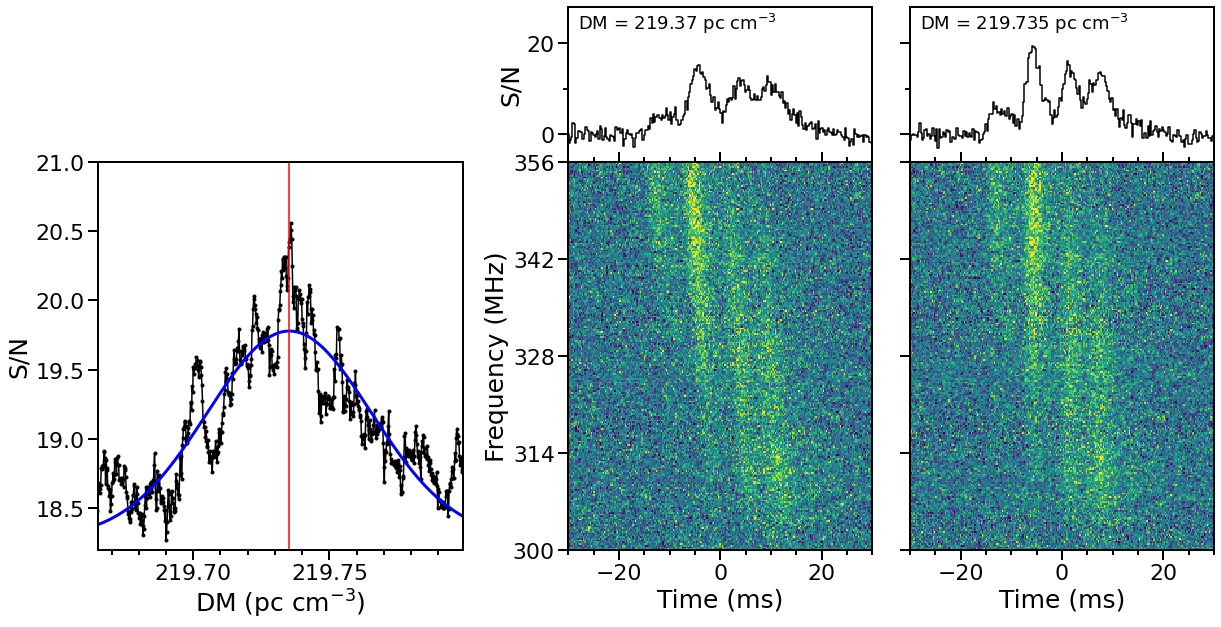

In [8]:
def waterfaller_dm(csv, burst):
    """
    --- ax6 ax1 ax2
    ax3 ax7 ax4 ax5
    
    ax6 and ax7 are there to give more space between the SN-DM plot and the dynamic spectrum
    Since there is no way to have different wspaces between plots
    
    Input is a csv file with the SN and DM values as run in the above cell
    the burst has to be a filpath and bursts are processed with YOUR and dedispersing code writting by Snelders
    """
    
    #Define the figure
    fig5 = plt.figure(figsize=(20,10))
    
    #Width 0.1 is for the hidden axes
    widths = [1.2, 0.1, 1, 1]
    heights = [1, 2.5]
    spec5 = fig5.add_gridspec(ncols=4, nrows=2, width_ratios=widths, height_ratios=heights,\
                              wspace=0.15, hspace=0.0)
    
    ax6 = fig5.add_subplot(spec5[0, 1])
    ax7 = fig5.add_subplot(spec5[1, 1 ])
    ax6.set_visible(False)
    ax7.set_visible(False)
    
    ###################################
    #DM / SN curve
    ax3 = fig5.add_subplot(spec5[1, 0])
    df = pd.read_csv(csv, sep=",", header=0, index_col=0)

    #Filter on the DM grid that has to be fitted, we don't want to take into account a wider dm-range 
    df_filter = df[(df['DM'] > 219.65) & (df['DM'] < 219.8)] 
    sn_filter = df_filter["SN"].values
    dm_filter = df_filter["DM"].values

    poptc,pcovc=curve_fit(gaus, dm_filter, sn_filter, p0=[20,219.7,0.1,200], maxfev=10000)
    
    #Retrieving the entire grid space from the df
    sn_range = df["SN"].values 
    dm_range = df["DM"].values 
    
    #Plotting the whole range
    ax3.plot(dm_range, sn_range,'.',color='k',ls='-')
    
    #Plotting only the gaussian
    dm_space = np.linspace(dm_filter[0], dm_filter[-1], 10000)
    ax3.plot(dm_space,gaus(dm_space,*poptc),color='b',lw=3,label='B128-Wb')
    ax3.axvline(poptc[1],color='red')
    ax3.set_xlabel(r'DM (pc cm$^{-3})$',size=25)
    ax3.set_ylabel('S/N',size=25)
    ax3.set_ylim(18.2,21)
    ax3.set_xlim(219.665,219.799)
    ax3.xaxis.set_minor_locator(ticker.MultipleLocator(0.01))
    
    ###################################
    ##DM = 219.37
    burst = your.Your(burst)
    
    tsamp = burst.your_header.tsamp #in seconds
    nbins = burst.your_header.nspectra 
    
    tmin = 0.0
    tmax = nbins * burst.tsamp # seconds
    fmin = np.min(burst.chan_freqs) - np.abs(burst.foff) / 2.0
    fmax = np.max(burst.chan_freqs) + np.abs(burst.foff) / 2.0
    extent_b = [tmin, tmax, fmin, fmax]
    
    offset = 2.629
    extent_b[0] = (tmin - offset) * 1000
    extent_b[1] = (tmax - offset) * 1000
    print(extent_b)
    #time increasing, freq decreasing
    print("loading in the data")
    d = burst.get_data(0,nbins,npoln=1)
    
    
    freqs = burst.chan_freqs # in Mhz
    
    print("de-de-dispersing")
    stokes_i_dd = dedisperse(d.T,-219.7,freqs,tsamp) 
    
    dm_dedisp = 219.37
    stokes_i = dedisperse(stokes_i_dd,dm_dedisp,freqs,tsamp)
    
    norm_v1=10 
    norm_v2=8000 
    stokes_i = normalize(stokes_i,stokes_i[:,norm_v1:norm_v2])
    
    stokes_i = downsample(stokes_i, freqf=8, timef=1)
    
    new_quantiles = np.percentile(stokes_i, (1, 99.9))
    
    #Create x grid to plot the step function. 
    x_grid = np.linspace(extent_b[0], extent_b[1], endpoint=False, num=nbins)
    
    #make profile
    prof = np.mean(stokes_i,axis=0)
    offprof = prof[norm_v1:norm_v2]
    offprof_std = np.std(offprof)
    offprof_mean = np.mean(offprof)   
    stokes_i_normprof = (prof - offprof_mean) / offprof_std
    #stokes_i_normprof = stokes_i_normprof[10000:10500] #hardcoded 60ms
    
    ###################################
    ##DM = 219.73
    ax4 = fig5.add_subplot(spec5[1, 2])
    ax4.imshow(stokes_i, aspect='auto', interpolation='None',\
          extent=extent_b, vmin=new_quantiles[0], vmax=new_quantiles[1])
    ax4.set_xlim(-30,30)
    ax4.set_ylabel('Frequency (MHz)',size=25)
    ax4.set_xlabel('Time (ms)',size=25)
    ax4.yaxis.set_major_locator(ticker.LinearLocator(5))
    ax4.xaxis.set_minor_locator(ticker.MultipleLocator(5))
    
    ax1 = fig5.add_subplot(spec5[0, 2], sharex=ax4)
    ax1.set_ylabel('S/N',size=25)
    ax1.plot(x_grid, stokes_i_normprof, drawstyle='steps-mid', color='black')
    ax1.text(-28,23, f"DM = 219.37" + r" pc cm$^{-3}$", fontsize=18)
    
    dm_dedisp = 219.76
    stokes_i = dedisperse(stokes_i_dd,dm_dedisp,freqs,tsamp)

    norm_v1=10 
    norm_v2=8000 
    stokes_i = normalize(stokes_i,stokes_i[:,norm_v1:norm_v2])
    stokes_i = downsample(stokes_i, freqf=8, timef=1)
    
    #Create x grid to plot the step function. 
    x_grid = np.linspace(extent_b[0], extent_b[1], endpoint=False, num=nbins)
    
    #make profile
    prof = np.mean(stokes_i,axis=0)
    offprof = prof[norm_v1:norm_v2]
    offprof_std = np.std(offprof)
    offprof_mean = np.mean(offprof)   
    stokes_i_normprof = (prof - offprof_mean) / offprof_std
    
    #stokes_i_normprof = stokes_i_normprof[10000:10500] #hardcoded 60ms
    
    ax5 = fig5.add_subplot(spec5[1, 3])
    ax5.imshow(stokes_i, aspect='auto', interpolation='None',\
          extent=extent_b, vmin=new_quantiles[0], vmax=new_quantiles[1])
    ax5.set_xlabel('Time (ms)',size=25)
    ax5.yaxis.set_major_locator(ticker.LinearLocator(5))
    ax5.xaxis.set_minor_locator(ticker.MultipleLocator(5))
    ax5.set_xlim(-30,30)
    
    ax2 = fig5.add_subplot(spec5[0, 3], sharex=ax5, sharey=ax1)        
    ax2.plot(x_grid, stokes_i_normprof, drawstyle='steps-mid', color='black')
    
    #Ticks on the SN-
    maxSN = np.ceil(np.max(stokes_i_normprof))
    yticks_sn=np.array([0,maxSN])
    ax2.set_yticks(yticks_sn)
    ax2.yaxis.set_minor_locator(ticker.MultipleLocator(10))
    ax2.set_ylim(-6,maxSN+8)
    
    ax2.text(-28,23, f"DM = 219.735" + r" pc cm$^{-3}$", fontsize=18)
        
    
    #Setting labels and ticks 
    for ax in [ax1,ax2,ax3,ax4,ax5]:
        
        ax.tick_params(labelsize=22) 
        
        for axis in ['top','bottom','left','right']:
            ax.spines[axis].set_linewidth(2)

            ax.tick_params(axis='y', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='y', which='minor', direction='out', length=5, width=2)
            ax.tick_params(axis='x', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='x', which='minor', direction='out', length=5, width=2)
    
    for ax in [ax1, ax2]:
        
        ax.tick_params(labelbottom=False)
        ax.tick_params(axis='x', which='major', direction='in', length=10, width=2)
        ax.tick_params(axis='x', which='minor', direction='in', length=5, width=2)
        
    ax2.tick_params(labelleft=False)
    ax5.tick_params(labelleft=False)
    
    plot_name = "pband_dm_compare"
    fig5.savefig(plot_name + ".pdf", dpi=600, bbox_inches='tight')
    
    fig5.savefig(plot_name + ".png", facecolor='white', \
            transparent=False, format = 'png',bbox_inches='tight', dpi=600)
    return

waterfaller_dm(csv="dm-trials-21937.csv",\
               burst='/data1/omar/sfxc/r117/p11749_30_p/p11749_30_256us_32KHz_StokesI_DM2197_cor_Wb.fil')